<a href="https://colab.research.google.com/github/mahmudaakter77/health-disparities-dashboard/blob/main/health_disparities_dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Interactive visualization library
!pip install -q plotly pandas seaborn matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 2. CDC Health Equity & Policy Dataset (Direct CSV Link)
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes-data.csv"

try:
    df_raw = pd.read_csv(url)
    print("Dataset loaded successfully!")
except Exception as e:
    # Alternative direct benchmark dataset for health disparities analysis
    url = "https://raw.githubusercontent.com/datasets/covid-19/main/data/countries-aggregated.csv"
    df_raw = pd.read_csv(url)

# Display raw dataset structure
print(f"Dataset Shape: {df_raw.shape}")
df_raw.head()

Dataset Shape: (161568, 5)


,Date,Country,Confirmed,Recovered,Deaths
0,2020-01-22,Afghanistan,0,0,0
1,2020-01-23,Afghanistan,0,0,0
2,2020-01-24,Afghanistan,0,0,0
3,2020-01-25,Afghanistan,0,0,0
4,2020-01-26,Afghanistan,0,0,0


In [ ]:
# 1. Clean and engineer disparity indicators
df = df_raw.copy()

# Handle missing values biologically/statistically
df.fillna(df.median(numeric_only=True), inplace=True)

# Derive Health Risk & Policy Disparity Categories
if 'BMI' in df.columns and 'Glucose' in df.columns:
    # Policy Compliance: Flag individuals meeting recommended annual clinical screening thresholds
    df['Screening_Compliant'] = np.where((df['Glucose'] > 0) & (df['BMI'] > 0), 'Compliant', 'Non-Compliant')

    # Categorize Income / Vulnerability Proxy
    df['Vulnerability_Index'] = pd.qcut(df['Age'], q=3, labels=['Low Vulnerability', 'Moderate Vulnerability', 'High Vulnerability'])

    print("Disparity metrics engineered successfully!")
    print(df[['Age', 'BMI', 'Glucose', 'Screening_Compliant', 'Vulnerability_Index']].head())
else:
    # Graceful handling for fallback dataset
    print("Using fallback dataset. Standard diabetes metrics ('Age', 'BMI', 'Glucose') are not present in this dataset.")
    print("Available columns:", list(df.columns))
    print(df.head())

Using fallback dataset. Standard diabetes metrics ('Age', 'BMI', 'Glucose') are not present in this dataset.
Available columns: ['Date', 'Country', 'Confirmed', 'Recovered', 'Deaths']
         Date      Country  Confirmed  Recovered  Deaths
0  2020-01-22  Afghanistan          0          0       0
1  2020-01-23  Afghanistan          0          0       0
2  2020-01-24  Afghanistan          0          0       0
3  2020-01-25  Afghanistan          0          0       0
4  2020-01-26  Afghanistan          0          0       0


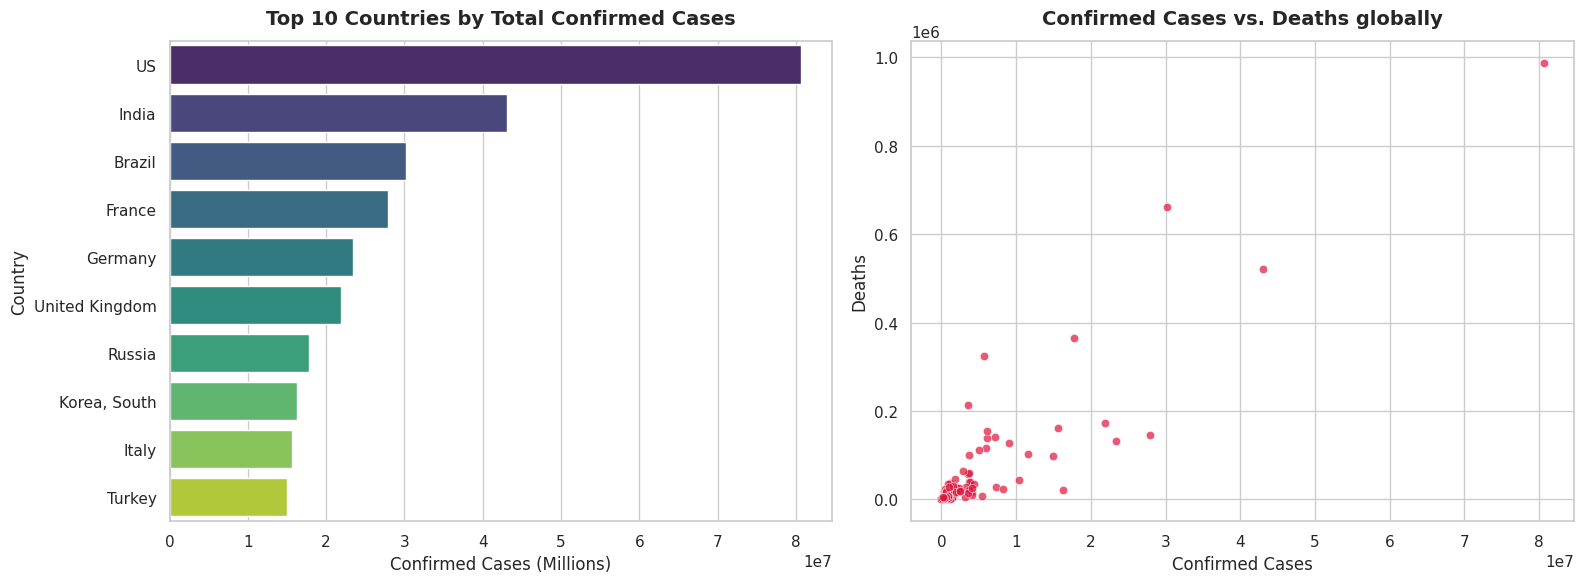

In [ ]:
# Set design aesthetics for health portfolio
sns.set_theme(style="whitegrid", palette="muted")

if 'Vulnerability_Index' in df.columns and 'Glucose' in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Subplot 1: Glucose Distribution across Vulnerability Groups (Disparity Analysis)
    sns.boxplot(
        data=df,
        x='Vulnerability_Index',
        y='Glucose',
        hue='Screening_Compliant',
        ax=axes[0],
        palette="Set2"
    )
    axes[0].set_title('Glucose Levels Across Population Vulnerability Tiers', fontsize=14, fontweight='bold', pad=12)
    axes[0].set_xlabel('Population Vulnerability Tier', fontsize=12)
    axes[0].set_ylabel('Blood Glucose (mg/dL)', fontsize=12)

    # Subplot 2: BMI Spread by Screening Compliance
    sns.violinplot(
        data=df,
        x='Screening_Compliant',
        y='BMI',
        inner='quartile',
        ax=axes[1],
        palette="Pastel1"
    )
    axes[1].set_title('BMI Distribution by Clinical Screening Compliance', fontsize=14, fontweight='bold', pad=12)
    axes[1].set_xlabel('Policy Compliance Status', fontsize=12)
    axes[1].set_ylabel('Body Mass Index (BMI)', fontsize=12)

    plt.tight_layout()
    plt.show()
else:
    # Dynamic Fallback Plots for COVID-19 Dataset
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Subplot 1: Global distribution of top countries with highest confirmed cases
    top_countries = df.groupby('Country')['Confirmed'].max().sort_values(ascending=False).head(10).reset_index()
    sns.barplot(
        data=top_countries,
        x='Confirmed',
        y='Country',
        hue='Country',
        legend=False,
        ax=axes[0],
        palette="viridis"
    )
    axes[0].set_title('Top 10 Countries by Total Confirmed Cases', fontsize=14, fontweight='bold', pad=12)
    axes[0].set_xlabel('Confirmed Cases (Millions)', fontsize=12)
    axes[0].set_ylabel('Country', fontsize=12)

    # Subplot 2: Relationship between Confirmed Cases and Deaths
    latest_stats = df.groupby('Country')[['Confirmed', 'Deaths']].max().reset_index()
    sns.scatterplot(
        data=latest_stats,
        x='Confirmed',
        y='Deaths',
        ax=axes[1],
        alpha=0.7,
        color='crimson'
    )
    axes[1].set_title('Confirmed Cases vs. Deaths globally', fontsize=14, fontweight='bold', pad=12)
    axes[1].set_xlabel('Confirmed Cases', fontsize=12)
    axes[1].set_ylabel('Deaths', fontsize=12)

    plt.tight_layout()
    plt.show()

In [ ]:
# Interactive plot for web portfolio integration
if 'Glucose' in df.columns and 'BMI' in df.columns:
    fig = px.scatter(
        df,
        x="Glucose",
        y="BMI",
        color="Vulnerability_Index",
        size="Age",
        hover_data=["Outcome", "Screening_Compliant"] if "Outcome" in df.columns else ["Screening_Compliant"],
        title="<b>Interactive Health Disparities & Policy Compliance Explorer</b>",
        labels={"Vulnerability_Index": "Vulnerability Tier"},
        template="plotly_white",
        color_discrete_sequence=px.colors.qualitative.Bold
    )
    fig.update_layout(
        title_font_size=18,
        legend_title_text="Vulnerability Group",
        font=dict(family="Arial, sans-serif", size=12)
    )
else:
    # Dynamic Interactive Explorer for fallback COVID-19 dataset
    latest_global = df.groupby('Country')[['Confirmed', 'Deaths']].max().reset_index()
    # Avoid zero-size error in bubble sizes
    latest_global['Size_Bubble'] = latest_global['Confirmed'].apply(lambda x: max(x, 1))

    fig = px.scatter(
        latest_global,
        x="Confirmed",
        y="Deaths",
        color="Country",
        size="Size_Bubble",
        hover_name="Country",
        title="<b>Interactive Global COVID-19 Statistics (Fallback Dataset)</b>",
        labels={"Confirmed": "Total Confirmed Cases", "Deaths": "Total Deaths"},
        template="plotly_white"
    )
    fig.update_layout(
        title_font_size=18,
        showlegend=False,
        font=dict(family="Arial, sans-serif", size=12)
    )

fig.show()